# RandomForest_Base — the MloHub Demand-Forecasting ML Engine
**ICS 3202 Artificial Intelligence · Project Deliverable 2 (CAT 2)**
**Group:** 18 &nbsp;|&nbsp; **Members:** 189946-Jason Kuria Wainaina, 189983-Kioko John Musyimi 176833-Michelle Wachanga Wangui &nbsp;|&nbsp; **Project:** MloHub (multi-tenant food ordering + business intelligence)


| Deliverable task | Where it is answered |
|---|---|
| 1. ML approach + algorithms | Shared Google spreadsheet |
| 2. Data cleaning from exploration to final dataset + at least 4 EDA observations | **Task 2** (2.1 – 2.8) |
| 3. Modelling approach on the base model + validity measures | **Task 3** (3.1 – 3.6) |
| 4. Other methods to validate the base model (compare models, same process) | **Task 4** (4.1 – 4.2) |

**Honesty note:** all data here is **synthetic** (made by our own simulator, no real customers).

## Setup and reproducibility
We fix a random **seed** so every group member gets exactly the same data and the same results.

In [1]:
from dataclasses import dataclass
from pathlib import Path
import json, hashlib, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import ParameterGrid
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

@dataclass(frozen=True)
class Config:
    project_folder: str = "MLOHub_AI_Research"
    seed: int = 2026
    start_date: str = "2024-01-01"
    days: int = 730
    timezone: str = "Africa/Nairobi"
    train_fraction: float = 0.70       # earliest 70% of DATES  -> training
    validation_fraction: float = 0.15  # next 15% of DATES      -> validation (last 15% -> test)

CFG = Config()
rng = np.random.default_rng(CFG.seed)          # used by the data simulator

# Google Colab -> mount Drive ; otherwise -> local folder
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive") / CFG.project_folder
except ImportError:
    ROOT = Path.cwd() / (CFG.project_folder + "_LOCAL")

RAW, QUALITY, CLEAN, FEAT, MODELS, FIGS, PREDS, REPORTS = [ROOT / n for n in
    ("01_raw", "02_quality", "03_clean", "04_features", "05_models", "06_figures", "07_predictions", "08_reports")]
for f in (RAW, QUALITY, CLEAN, FEAT, MODELS, FIGS, PREDS, REPORTS):
    f.mkdir(parents=True, exist_ok=True)

print("Research folder :", ROOT.resolve())
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("Seed:", CFG.seed)

Mounted at /content/drive
Research folder : /content/drive/MyDrive/MLOHub_AI_Research
Python 3.13.18 | pandas 2.2.3 | numpy 2.1.3 | scikit-learn 1.6.1
Seed: 2026


## Where the data comes from
MloHub has no real customers yet, so we **simulate** orders with a written, repeatable recipe:

1. 3 fictional restaurants, 12 dishes each (36 menu items) with a base daily demand and a price.
2. 730 consecutive days in the `Africa/Nairobi` time zone.
3. Expected portions = base demand × restaurant size × yearly wave × slow growth × weekday/weekend effect (every dish dips at weekends, but Samosa, Fresh Juice and Fruit Salad dip **less** than the others).
4. Real demand is never exact, so the actual number is drawn from a **negative-binomial** distribution (whole numbers, more spread than a constant).
5. Each day's portions are split into order lines of 1–4 portions with a timestamp, so the result looks like a real order table.



In [2]:
def generate_synthetic_tables(cfg, rng):
    """Simulate restaurants, menu, orders and order lines. Returns 4 DataFrames + the calendar."""
    dates = pd.date_range(cfg.start_date, periods=cfg.days, freq="D", tz=cfg.timezone)
    restaurants = pd.DataFrame([
        {"id": 1, "slug": "campus-bites",      "name": "Campus Bites"},
        {"id": 2, "slug": "demo-kitchen-east", "name": "Demo Kitchen East (synthetic)"},
        {"id": 3, "slug": "demo-kitchen-west", "name": "Demo Kitchen West (synthetic)"}])
    menu   = ["Chicken Pilau", "Beef Stew", "Vegetable Rice", "Samosa", "Fresh Juice", "Chapati Beans",
              "Ugali Sukuma", "Rice Beans", "Egg Sandwich", "Tea", "Mandazi", "Fruit Salad"]
    base   = [24, 19, 16, 20, 15, 17, 14, 13, 11, 28, 22, 10]       # typical portions/day
    prices = [350, 420, 280, 80, 150, 200, 180, 180, 160, 60, 40, 170]  # KSh
    rows = []
    for r in restaurants.itertuples(index=False):
        for i, (name, price) in enumerate(zip(menu, prices)):
            rows.append({"id": r.id * 100 + i + 1, "restaurant_id": r.id, "slug": name.lower().replace(" ", "-"),
                         "name": name, "price": price, "is_available": True, "base_demand": base[i]})
    food = pd.DataFrame(rows)

    order_rows, item_rows, oid, lid = [], [], 1, 1
    for d in dates:
        dow = d.dayofweek
        annual = 1 + 0.14 * np.sin(2 * np.pi * d.dayofyear / 365.25)       # yearly wave
        trend  = 1 + 0.10 * ((d - dates[0]).days / (cfg.days - 1))          # slow growth (+10% over 2 years)
        for f in food.itertuples(index=False):
            tenant  = {1: 1.0, 2: 0.77, 3: 1.22}[f.restaurant_id]           # restaurant size
            weekend = 0.78 if dow >= 5 else 1.10
            dish_we = 1.28 if (f.name in ("Samosa", "Fresh Juice", "Fruit Salad") and dow >= 5) else 1.0
            expected = max(0.5, f.base_demand * tenant * annual * trend * weekend * dish_we)
            portions = int(rng.negative_binomial(10, 10 / (10 + expected)))  # random whole-number demand
            remaining = portions
            while remaining > 0:                                             # split into order lines of 1-4
                q = min(remaining, int(rng.integers(1, 5)))
                stamp = d + pd.Timedelta(hours=int(rng.integers(8, 20)), minutes=int(rng.integers(0, 60)))
                method = "PICKUP" if rng.random() < 0.58 else "DELIVERY"
                order_rows.append((oid, f.restaurant_id, "COMPLETED", method, stamp.isoformat()))
                item_rows.append((lid, oid, f.id, f.name, f.price, q))
                remaining -= q; oid += 1; lid += 1
    orders = pd.DataFrame(order_rows, columns=["id", "restaurant_id", "status", "fulfilment_method", "created_at"])
    items  = pd.DataFrame(item_rows,  columns=["id", "order_id", "food_item_id", "food_item_name", "unit_price", "quantity"])
    return restaurants, food.drop(columns=["base_demand"]), orders, items, dates

names = ["restaurants_synthetic.csv", "food_items_synthetic.csv", "orders_synthetic.csv", "order_items_synthetic.csv"]
if all((RAW / n).is_file() for n in names):
    print("Source CSVs already exist in 01_raw -> reloading them (delete the files to regenerate).")
    DATES = pd.date_range(CFG.start_date, periods=CFG.days, freq="D", tz=CFG.timezone)
else:
    print("Generating synthetic data (takes ~10-30 s) ...")
    R, F, O, I, DATES = generate_synthetic_tables(CFG, rng)
    R.to_csv(RAW / names[0], index=False); F.to_csv(RAW / names[1], index=False)
    O.to_csv(RAW / names[2], index=False); I.to_csv(RAW / names[3], index=False)
    print("Saved four source CSVs to", RAW.resolve())

Generating synthetic data (takes ~10-30 s) ...
Saved four source CSVs to /content/drive/MyDrive/MLOHub_AI_Research/01_raw


## Task 2 · Data cleaning and EDA: from exploration to the final dataset

### 2.1 Explore the raw data

Table meaning: `restaurants` (vendors) · `food_items` (menu) · `orders` (one order) · `order_items` (what was in the order: dish, price, quantity).

In [3]:
restaurants = pd.read_csv(RAW / "restaurants_synthetic.csv")
food        = pd.read_csv(RAW / "food_items_synthetic.csv")
orders      = pd.read_csv(RAW / "orders_synthetic.csv")
source_items= pd.read_csv(RAW / "order_items_synthetic.csv")      # the pristine original (kept untouched)

for name, df in [("restaurants", restaurants), ("food_items", food), ("orders", orders), ("order_items", source_items)]:
    print(f"{name:12s}: {len(df):>8,} rows x {df.shape[1]} columns | missing cells: {int(df.isna().sum().sum())}")

print("\nFirst five order lines:")
display(source_items.head())
print("Column types:"); source_items.info()
print("\nRelationship checks on the original source tables:")
assert source_items["id"].is_unique
assert source_items["order_id"].isin(orders["id"]).all()
assert source_items["food_item_id"].isin(food["id"]).all()
print("  every order line points to a real order and a real dish  -> PASS")

restaurants :        3 rows x 3 columns | missing cells: 0
food_items  :       36 rows x 6 columns | missing cells: 0
orders      :  206,845 rows x 5 columns | missing cells: 0
order_items :  206,845 rows x 6 columns | missing cells: 0

First five order lines:


,id,order_id,food_item_id,food_item_name,unit_price,quantity
0,1,1,101,Chicken Pilau,350,3
1,2,2,101,Chicken Pilau,350,4
2,3,3,101,Chicken Pilau,350,1
3,4,4,101,Chicken Pilau,350,4
4,5,5,101,Chicken Pilau,350,1


Column types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206845 entries, 0 to 206844
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   id              206845 non-null  int64 
 1   order_id        206845 non-null  int64 
 2   food_item_id    206845 non-null  int64 
 3   food_item_name  206845 non-null  object
 4   unit_price      206845 non-null  int64 
 5   quantity        206845 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 9.5+ MB

Relationship checks on the original source tables:
  every order line points to a real order and a real dish  -> PASS


### 2.2 Practise cleaning on a messy copy
| Injected error | Count | Why it happens in real life |
|---|---|---|
| Quantity left blank | 20 | Staff skipped a field |
| Quantity typed with spaces `" 2 "` | 15 | Text typed into a number field |
| Negative quantity `-5` | 15 | Keying error / refund recorded wrongly |
| Unknown dish id `999999` | 15 | Dish deleted or wrong id |
| Quantity as text `"unknown"` | 15 | Free text typed in |
| Negative price `-20` | 10 | Keying error |
| Duplicated rows | 15 | Same export imported twice |



In [4]:
rng_dirty = np.random.default_rng(CFG.seed + 1)            # separate seed so dirty data is reproducible on its own
dirty = source_items.copy()
dirty["quantity"] = dirty["quantity"].astype(object)
pick = rng_dirty.choice(dirty.index, size=90, replace=False)
dirty.loc[pick[:20],   "quantity"]     = None
dirty.loc[pick[20:35], "quantity"]     = " 2 "
dirty.loc[pick[35:50], "quantity"]     = -5
dirty.loc[pick[50:65], "food_item_id"] = 999999
dirty.loc[pick[65:80], "quantity"]     = "unknown"
dirty.loc[pick[80:90], "unit_price"]   = -20
dirty = pd.concat([dirty, dirty.loc[pick[:15]]], ignore_index=True)      # 15 duplicated rows
RAW_DIRTY_PATH = RAW / "order_items_RAW_DIRTY.csv"
dirty.to_csv(RAW_DIRTY_PATH, index=False)
print("Saved", RAW_DIRTY_PATH.name, "-", f"{len(dirty):,}", "rows (original had", f"{len(source_items):,})")

Saved order_items_RAW_DIRTY.csv - 206,860 rows (original had 206,845)


### 2.3 Audit — inspect the dirty file **without changing it**
We reload the saved CSV (the handoff point), look at its types and then *count* every kind of problem. Counts can overlap (one row can have two problems), so they must not be simply added up.

RAW dirty file: 206,860 rows


,id,order_id,food_item_id,food_item_name,unit_price,quantity
0,1,1,101,Chicken Pilau,350,3
1,2,2,101,Chicken Pilau,350,4
2,3,3,101,Chicken Pilau,350,1
3,4,4,101,Chicken Pilau,350,4
4,5,5,101,Chicken Pilau,350,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206860 entries, 0 to 206859
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   id              206860 non-null  int64 
 1   order_id        206860 non-null  int64 
 2   food_item_id    206860 non-null  int64 
 3   food_item_name  206860 non-null  object
 4   unit_price      206860 non-null  int64 
 5   quantity        206825 non-null  object
dtypes: int64(4), object(2)
memory usage: 9.5+ MB


,affected_rows
duplicate_id,15
missing_quantity,35
nonnumeric_quantity,15
nonpositive_or_fractional_quantity,15
invalid_food_id,15
invalid_order_id,0
invalid_price,10
cross_restaurant_mismatch,0


Rows with at least one problem: 90 of 206,860 (0.044%)


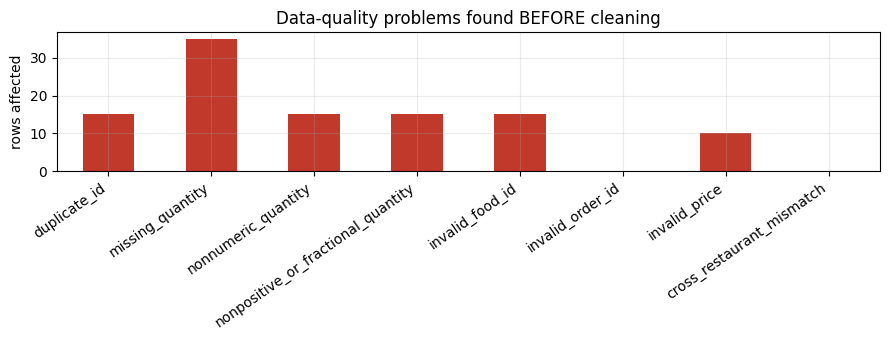

In [5]:
raw_lines = pd.read_csv(RAW_DIRTY_PATH, low_memory=False)
print("RAW dirty file:", f"{len(raw_lines):,}", "rows")
display(raw_lines.head())
raw_lines.info()

q = pd.to_numeric(raw_lines["quantity"], errors="coerce")       # text like "unknown" -> NaN so we can detect it
p = pd.to_numeric(raw_lines["unit_price"], errors="coerce")
order_tenant = orders.set_index("id")["restaurant_id"]
food_tenant  = food.set_index("id")["restaurant_id"]
ot = raw_lines["order_id"].map(order_tenant); ft = raw_lines["food_item_id"].map(food_tenant)

flags = pd.DataFrame(index=raw_lines.index)
flags["duplicate_id"]                       = raw_lines.duplicated("id", keep="first")
flags["missing_quantity"]                   = raw_lines["quantity"].isna()
flags["nonnumeric_quantity"]                = q.isna() & raw_lines["quantity"].notna()
flags["nonpositive_or_fractional_quantity"] = q.notna() & ((q <= 0) | (q % 1 != 0))
flags["invalid_food_id"]                    = ~raw_lines["food_item_id"].isin(food["id"])
flags["invalid_order_id"]                   = ~raw_lines["order_id"].isin(orders["id"])
flags["invalid_price"]                      = p.isna() | (p < 0)
flags["cross_restaurant_mismatch"]          = ot.notna() & ft.notna() & ot.ne(ft)

audit = flags.sum().rename("affected_rows").to_frame()
display(audit)
print("Rows with at least one problem:", int(flags.any(axis=1).sum()), "of", f"{len(raw_lines):,}",
      f"({100*flags.any(axis=1).mean():.3f}%)")
ax = audit["affected_rows"].plot(kind="bar", figsize=(9, 3.5), color="#c0392b")
ax.set_title("Data-quality problems found BEFORE cleaning"); ax.set_ylabel("rows affected")
plt.xticks(rotation=35, ha="right"); plt.tight_layout()
plt.savefig(FIGS / "01_quality_audit.png", dpi=140); plt.show()
audit.to_csv(QUALITY / "raw_data_quality_report.csv")

### 2.4 Clean — repair, quarantine, reconcile
Repair what is safe, quarantine what is not, and prove every row is accounted for.

In [6]:
deduped = raw_lines.drop_duplicates("id", keep="first").copy()
duplicates_removed = len(raw_lines) - len(deduped)
deduped["quantity"]   = pd.to_numeric(deduped["quantity"],   errors="coerce")
deduped["unit_price"] = pd.to_numeric(deduped["unit_price"], errors="coerce")
ot = deduped["order_id"].map(order_tenant); ft = deduped["food_item_id"].map(food_tenant)

invalid = (deduped["quantity"].isna() | (deduped["quantity"] <= 0) | (deduped["quantity"] % 1 != 0) |
           deduped["unit_price"].isna() | (deduped["unit_price"] < 0) |
           ~deduped["order_id"].isin(orders["id"]) | ~deduped["food_item_id"].isin(food["id"]) |
           (ot.notna() & ft.notna() & ot.ne(ft)))

quarantine = deduped.loc[invalid].copy()
cleaned    = deduped.loc[~invalid].copy()
cleaned["quantity"] = cleaned["quantity"].astype(int)
cleaned = cleaned.sort_values("id").reset_index(drop=True)

cleaned.to_csv(CLEAN / "order_items_CLEANED.csv", index=False)
quarantine.to_csv(QUALITY / "order_items_QUARANTINED.csv", index=False)

reconciliation = pd.DataFrame([
    {"stage": "RAW imported rows",           "rows": len(raw_lines)},
    {"stage": "- duplicates removed",        "rows": duplicates_removed},
    {"stage": "- quarantined (invalid)",     "rows": len(quarantine)},
    {"stage": "= CLEAN usable rows",         "rows": len(cleaned)}])
display(reconciliation)
assert len(raw_lines) == duplicates_removed + len(quarantine) + len(cleaned)       # nothing disappeared silently
assert cleaned["id"].is_unique and cleaned["quantity"].gt(0).all() and cleaned["unit_price"].ge(0).all()
reconciliation.to_csv(QUALITY / "cleaning_reconciliation.csv", index=False)
print(f"Removed in total: {len(raw_lines)-len(cleaned):,} rows = {100*(1-len(cleaned)/len(raw_lines)):.3f}% of the raw file")
print("Quarantine reasons (rows may have several):")
display(flags.loc[deduped.index[invalid.values]].sum().loc[lambda s: s > 0].rename("rows").to_frame())

,stage,rows
0,RAW imported rows,206860
1,- duplicates removed,15
2,- quarantined (invalid),75
3,= CLEAN usable rows,206770


Removed in total: 90 rows = 0.044% of the raw file
Quarantine reasons (rows may have several):


,rows
missing_quantity,20
nonnumeric_quantity,15
nonpositive_or_fractional_quantity,15
invalid_food_id,15
invalid_price,10


### 2.5 Reload the clean file and compare it with the raw one
A cleaned file is a **new dataset with a known history**, so we load it back from disk (not from memory) and check the before/after picture.

CLEAN rows: 206,770 | RAW rows: 206,860


,quantity,unit_price
count,206770.00,206770.0
mean,2.37,185.7
std,1.11,118.9
min,1.00,40.0
25%,1.00,80.0
50%,2.00,170.0
75%,3.00,280.0
max,4.00,420.0


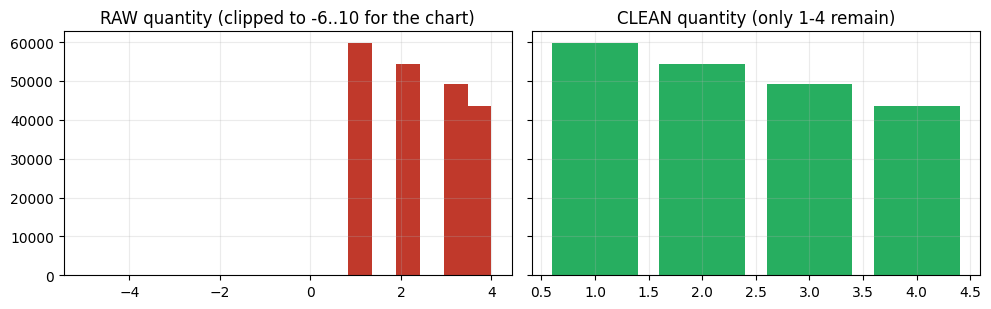

In [7]:
order_items = pd.read_csv(CLEAN / "order_items_CLEANED.csv")
print("CLEAN rows:", f"{len(order_items):,}", "| RAW rows:", f"{len(raw_lines):,}")
display(order_items[["quantity", "unit_price"]].describe().round(2))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
pd.to_numeric(raw_lines["quantity"], errors="coerce").dropna().clip(-6, 10).hist(ax=ax[0], bins=17, color="#c0392b")
ax[0].set_title("RAW quantity (clipped to -6..10 for the chart)")
order_items["quantity"].hist(ax=ax[1], bins=range(1, 6), color="#27ae60", align="left", rwidth=.8)
ax[1].set_title("CLEAN quantity (only 1-4 remain)"); plt.tight_layout(); plt.show()

### 2.6 Critical check — did cleaning bias the demand?
Because we still hold the pristine original, we can **measure the damage** cleaning did (in real life you cannot). Two effects exist: quarantined rows remove some real sales (demand looks a bit lower), and repairing `" 2 "` forces quantity = 2 even if the true value was different. We compare *total daily demand* before and after.

In [8]:
def build_daily(items, orders, food, dates):
    """order lines -> ONE row per (date, restaurant, dish) with total portions sold. Zero-sale days are kept as 0."""
    j = items.merge(orders[["id", "restaurant_id", "created_at"]], left_on="order_id", right_on="id", suffixes=("", "_order"))
    j = j.merge(food[["id", "restaurant_id"]], left_on="food_item_id", right_on="id", suffixes=("", "_food"))
    assert (j["restaurant_id"] == j["restaurant_id_food"]).all(), "cross-restaurant order line found"
    j["date"] = (pd.to_datetime(j["created_at"], utc=True).dt.tz_convert("Africa/Nairobi")
                   .dt.tz_localize(None).dt.normalize())
    agg = (j.groupby(["date", "restaurant_id", "food_item_id"], as_index=False)["quantity"].sum()
             .rename(columns={"quantity": "quantity_sold"}))
    grid = pd.MultiIndex.from_product([dates.tz_localize(None).normalize(), food["id"]],
                                      names=["date", "food_item_id"]).to_frame(index=False)
    grid = grid.merge(food[["id", "restaurant_id"]].rename(columns={"id": "food_item_id"}), on="food_item_id")
    daily = grid.merge(agg, on=["date", "restaurant_id", "food_item_id"], how="left")
    daily["quantity_sold"] = daily["quantity_sold"].fillna(0).astype(int)
    return daily

daily_clean  = build_daily(order_items,  orders, food, DATES)      # what we will model
daily_truth  = build_daily(source_items, orders, food, DATES)      # pristine reference (only possible in a simulation)

lost = daily_truth["quantity_sold"].sum() - daily_clean["quantity_sold"].sum()
diff = (daily_truth["quantity_sold"] - daily_clean["quantity_sold"]).abs()
print(f"Total portions  truth: {daily_truth.quantity_sold.sum():,} | cleaned: {daily_clean.quantity_sold.sum():,} | difference: {lost:,} ({100*lost/daily_truth.quantity_sold.sum():.3f}%)")
print(f"Daily rows changed by cleaning: {(diff>0).sum():,} of {len(diff):,}  | largest single-day error: {diff.max()} portions | mean error: {diff.mean():.4f}")
print("Conclusion: cleaning removed a very small share of demand, so bias is negligible here. With real data the same check must be repeated.")

Total portions  truth: 490,154 | cleaned: 489,963 | difference: 191 (0.039%)
Daily rows changed by cleaning: 87 of 26,280  | largest single-day error: 4 portions | mean error: 0.0075
Conclusion: cleaning removed a very small share of demand, so bias is negligible here. With real data the same check must be repeated.


### 2.7 From order lines to the modelling dataset
One **order line** = one purchase. One **modelling row** = *all portions of one dish at one restaurant on one day*. We add the **zero-sale days** too (otherwise demand would look higher than it is). Result: 3 restaurants × 12 dishes × 730 days = **26,280 rows**.

In [9]:
daily = daily_clean.copy()
assert len(daily) == CFG.days * len(food) and not daily.isna().any().any()
assert daily["quantity_sold"].sum() == order_items["quantity"].sum()            # no portion lost or invented in aggregation
daily = daily.merge(food[["id", "name"]].rename(columns={"id": "food_item_id", "name": "dish"}), on="food_item_id")
daily.to_csv(FEAT / "daily_demand_aggregated.csv", index=False)
print(f"Modelling table: {len(daily):,} rows | zero-sale share: {100*daily.quantity_sold.eq(0).mean():.2f}%")
display(daily.head())

Modelling table: 26,280 rows | zero-sale share: 0.03%


,date,food_item_id,restaurant_id,quantity_sold,dish
0,2024-01-01,101,1,19,Chicken Pilau
1,2024-01-01,102,1,20,Beef Stew
2,2024-01-01,103,1,23,Vegetable Rice
3,2024-01-01,104,1,20,Samosa
4,2024-01-01,105,1,18,Fresh Juice


### 2.8 Exploratory data analysis (EDA) — at least 4 observations
We ask the data questions and let **numbers + charts** answer. The observations below are computed by code, so they stay correct whatever the data.

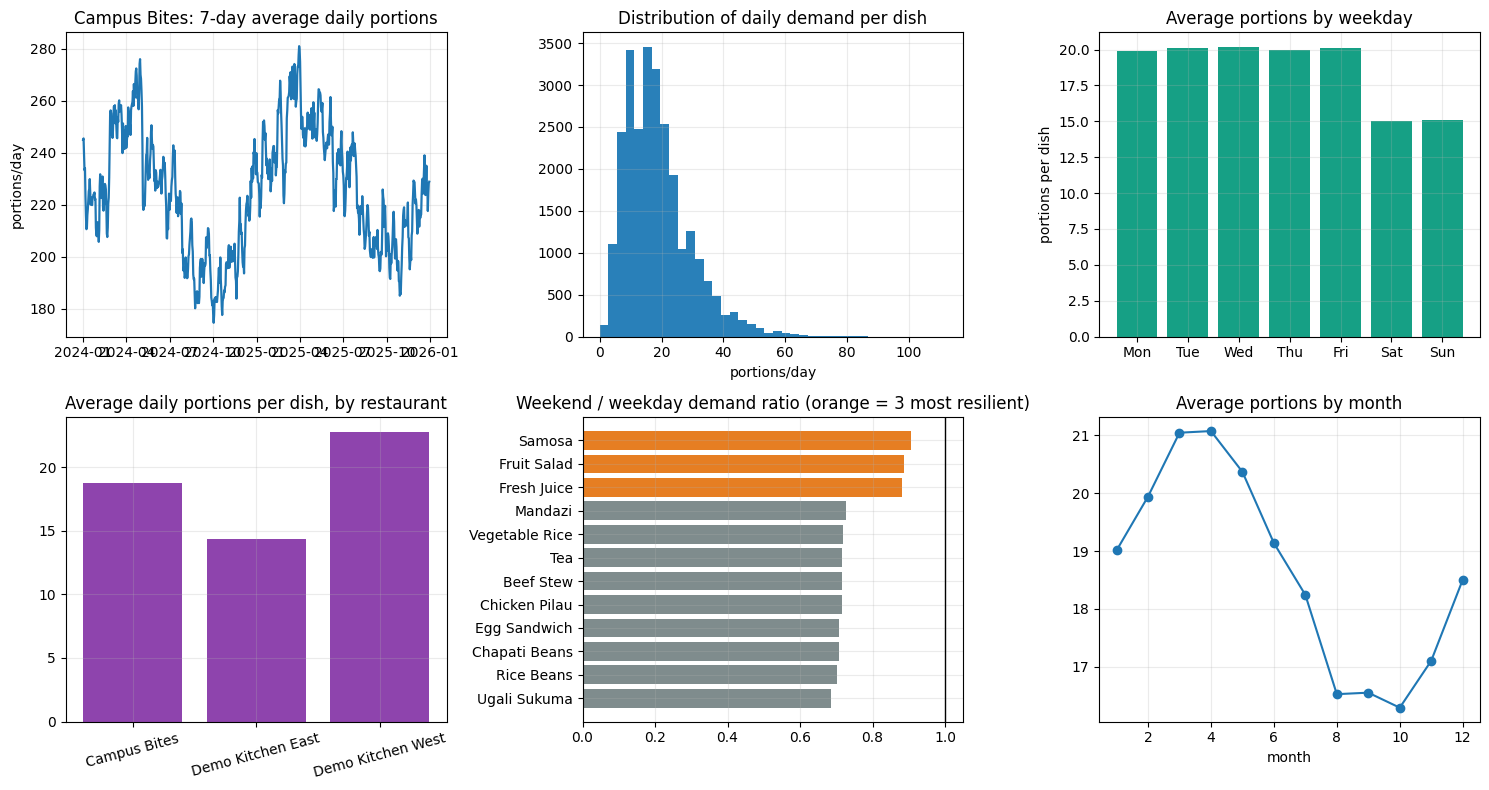

OBSERVATION 1 (weekly pattern): average demand is 20.1 portions on weekdays vs 15.1 on weekends (-25%), so weekends are slower overall.
   The drop is NOT equal for every dish: Samosa (0.91x), Fruit Salad (0.89x), Fresh Juice (0.88x) hold up best, while the other dishes fall to about 0.71x. The weekend effect differs by dish, so the model needs dish id AND is_weekend.
OBSERVATION 2 (restaurant size): Demo Kitchen West (synthetic) is the busiest (22.8 portions/dish/day) and Demo Kitchen East (synthetic) the quietest (14.4); restaurant identity must be a model feature.
OBSERVATION 3 (dish popularity): Tea is the top seller (29.6/day) and Fruit Salad the lowest (11.3/day).
OBSERVATION 4 (growth + season): average demand in 2025 (19.1) is +5.4% vs 2024 (18.2) - comparing full calendar years so the yearly wave cancels out -> a slow upward trend. Separately, the monthly chart peaks in month 4 and dips in month 10 (seasonality). Comparing the first 90 days with the last 90 would be misleading

In [10]:
daily["dow"]     = daily["date"].dt.dayofweek
daily["weekend"] = daily["dow"] >= 5
daily["month"]   = daily["date"].dt.month
rest_name = restaurants.set_index("id")["name"].to_dict()

fig, axs = plt.subplots(2, 3, figsize=(15, 8))

# (a) trend of one restaurant
campus = daily[daily.restaurant_id == 1].groupby("date")["quantity_sold"].sum()
axs[0, 0].plot(campus.index, campus.rolling(7, min_periods=1).mean(), lw=1.6)
axs[0, 0].set(title="Campus Bites: 7-day average daily portions", ylabel="portions/day")

# (b) distribution of daily demand
axs[0, 1].hist(daily.quantity_sold, bins=40, color="#2980b9")
axs[0, 1].set(title="Distribution of daily demand per dish", xlabel="portions/day")

# (c) weekday pattern
wk = daily.groupby("dow")["quantity_sold"].mean()
axs[0, 2].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], wk.values, color="#16a085")
axs[0, 2].set(title="Average portions by weekday", ylabel="portions per dish")

# (d) restaurant sizes
rest_tot = daily.groupby("restaurant_id")["quantity_sold"].mean()
axs[1, 0].bar([rest_name[i].replace(" (synthetic)", "") for i in rest_tot.index], rest_tot.values, color="#8e44ad")
axs[1, 0].set(title="Average daily portions per dish, by restaurant"); axs[1, 0].tick_params(axis="x", rotation=15)

# (e) weekend effect per dish (weekend mean / weekday mean)
ratio = (daily.groupby(["dish", "weekend"])["quantity_sold"].mean().unstack())
ratio = (ratio[True] / ratio[False]).sort_values()
axs[1, 1].barh(ratio.index, ratio.values, color=["#e67e22" if v >= ratio.iloc[-3] else "#7f8c8d" for v in ratio.values])
axs[1, 1].axvline(1, color="k", lw=1); axs[1, 1].set(title="Weekend / weekday demand ratio (orange = 3 most resilient)")

# (f) monthly seasonality
mo = daily.groupby("month")["quantity_sold"].mean()
axs[1, 2].plot(mo.index, mo.values, marker="o"); axs[1, 2].set(title="Average portions by month", xlabel="month")
plt.tight_layout(); plt.savefig(FIGS / "02_eda_overview.png", dpi=140); plt.show()

# ---------- observations computed from the data ----------
import calendar
wkday, wkend = daily.loc[~daily.weekend, "quantity_sold"].mean(), daily.loc[daily.weekend, "quantity_sold"].mean()
r_sorted = ratio.sort_values(ascending=False)
y1, y2 = [daily.loc[daily.date.dt.year == y, "quantity_sold"].mean() for y in sorted(daily.date.dt.year.unique())[:2]]
top, bottom = daily.groupby("dish")["quantity_sold"].mean().sort_values().iloc[[-1, 0]].items()
var_mean = daily.quantity_sold.var() / daily.quantity_sold.mean()
rs = rest_tot.sort_values()
pk, tr = mo.idxmax(), mo.idxmin()
hold_best = ratio.sort_values(ascending=False).head(3); others = ratio.drop(hold_best.index)
print("OBSERVATION 1 (weekly pattern): average demand is", f"{wkday:.1f}", "portions on weekdays vs", f"{wkend:.1f}",
      f"on weekends ({100*(wkend/wkday-1):+.0f}%), so weekends are slower overall.")
print("   The drop is NOT equal for every dish:", ", ".join(f"{d} ({r:.2f}x)" for d, r in hold_best.items()),
      f"hold up best, while the other dishes fall to about {others.mean():.2f}x. The weekend effect differs by dish, so the model needs dish id AND is_weekend.")
print("OBSERVATION 2 (restaurant size):", f"{rest_name[rs.index[-1]]} is the busiest ({rs.iloc[-1]:.1f} portions/dish/day) and",
      f"{rest_name[rs.index[0]]} the quietest ({rs.iloc[0]:.1f}); restaurant identity must be a model feature.")
print("OBSERVATION 3 (dish popularity):", f"{top[0]} is the top seller ({top[1]:.1f}/day) and {bottom[0]} the lowest ({bottom[1]:.1f}/day).")
y24 = daily[daily.date.dt.year == 2024]["quantity_sold"].mean(); y25 = daily[daily.date.dt.year == 2025]["quantity_sold"].mean()
print("OBSERVATION 4 (growth + season):", f"average demand in 2025 ({y25:.1f}) is {100*(y25/y24-1):+.1f}% vs 2024 ({y24:.1f}) - comparing full calendar years so the yearly wave cancels out -> a slow upward trend.",
      f"Separately, the monthly chart peaks in month {int(mo.idxmax())} and dips in month {int(mo.idxmin())} (seasonality). Comparing the first 90 days with the last 90 would be misleading because they fall in different seasons.")
print("OBSERVATION 5 (seasonality):", f"demand peaks around {calendar.month_name[pk]} ({mo[pk]:.1f}) and is lowest around {calendar.month_name[tr]} ({mo[tr]:.1f}), a swing of {100*(mo[pk]/mo[tr]-1):.0f}%,",
      "so the calendar month is a useful clue.")
print("OBSERVATION 6 (shape of demand):", f"variance/mean = {var_mean:.1f} (a value of 1 would be perfectly 'Poisson'); the histogram is right-skewed,",
      "so single days are noisy and we report error in portions (MAE).")
print("OBSERVATION 7 (zeros):", f"{100*daily.quantity_sold.eq(0).mean():.2f}% of dish-days have zero sales - tiny here, but each must be kept as 0, never dropped.")

**EDA takeaways — what we saw → why it matters for the model**

1. **Weekends are slower (−25%), but not equally for every dish.** Samosa, Fresh Juice and Fruit Salad dip less → one rule like "cut everything by 25% at weekends" would be wrong, so the model needs `is_weekend` AND the dish id.
2. **Restaurants differ in size** (Demo Kitchen West is busiest at 22.8 portions per dish per day, Demo Kitchen East quietest at 14.4) → `restaurant_id` must be a feature.
3. **Demand grows slowly (+5.4% in 2025 vs 2024) and follows a yearly wave** (peak around April, low around October, a 29% swing) → `month` and recent history are useful clues.
4. **Daily demand is noisy and right-skewed** (variance/mean = 6.0) → single days cannot be predicted exactly, so we report error in portions (MAE).

## Task 3 · Modelling approach for the base model (Random Forest) and its validity measures

### 3.1 Features — the clues the model sees (without cheating)
To predict day *t* the model may only use what is known **before** day *t*:

| Feature | Meaning | Known in advance? |
|---|---|---|
| `lag_1` | portions sold yesterday | ✅ |
| `lag_7` | portions sold on the same weekday last week | ✅ |
| `rolling_mean_7` | average of the **previous** 7 days (we shift by 1 so today is excluded) | ✅ |
| `day_of_week`, `month`, `is_weekend` | calendar | ✅ |
| `restaurant_id`, `food_item_id` | who and what | ✅ |

**Data leakage** = accidentally letting the answer into the clues (e.g. a 7-day average that includes the day we predict). It makes results look great and then fail in the real app. The `shift(1)` below prevents it, and we **prove** it with a test.

In [11]:
daily = daily.sort_values(["restaurant_id", "food_item_id", "date"]).reset_index(drop=True)
g = daily.groupby(["restaurant_id", "food_item_id"])["quantity_sold"]
daily["lag_1"]          = g.shift(1)
daily["lag_7"]          = g.shift(7)
daily["rolling_mean_7"] = g.transform(lambda s: s.shift(1).rolling(7, min_periods=7).mean())   # shift(1) = no leakage
daily["day_of_week"]    = daily["date"].dt.dayofweek
daily["month"]          = daily["date"].dt.month
daily["is_weekend"]     = (daily["day_of_week"] >= 5).astype(int)

# --- leakage test on one series: recompute the average by hand from the 7 days BEFORE the target day
s = daily[(daily.restaurant_id == 1) & (daily.food_item_id == 101)].reset_index(drop=True)
t = 40
assert np.isclose(s.loc[t, "rolling_mean_7"], s.loc[t-7:t-1, "quantity_sold"].mean())
assert s.loc[t, "lag_1"] == s.loc[t-1, "quantity_sold"] and s.loc[t, "lag_7"] == s.loc[t-7, "quantity_sold"]
print("Leakage test PASSED: features for day t use only days before t.")

ready = daily.dropna(subset=["lag_1", "lag_7", "rolling_mean_7"]).copy()       # first 7 days of every series lack history
ready["restaurant_id"] = ready["restaurant_id"].astype(str)
ready["food_item_id"]  = ready["food_item_id"].astype(str)
ready.to_csv(FEAT / "model_ready_features.csv", index=False)
FEATURES = ["restaurant_id", "food_item_id", "day_of_week", "month", "is_weekend", "lag_1", "lag_7", "rolling_mean_7"]
TARGET   = "quantity_sold"
print(f"Model-ready rows: {len(ready):,} (dropped {len(daily)-len(ready)} warm-up rows) | earliest date {ready.date.min().date()}")

# how useful are the clues? (simple correlation with the target)
print("\nCorrelation of each numeric clue with tomorrow's demand:")
display(ready[["lag_1", "lag_7", "rolling_mean_7", "is_weekend", "month", TARGET]].corr()[TARGET].drop(TARGET).round(3).to_frame("correlation"))

Leakage test PASSED: features for day t use only days before t.
Model-ready rows: 26,028 (dropped 252 warm-up rows) | earliest date 2024-01-08

Correlation of each numeric clue with tomorrow's demand:


,correlation
lag_1,0.433
lag_7,0.470
rolling_mean_7,0.591
is_weekend,-0.213
month,-0.116


### 3.2 Chronological train / validation / test split
**Train** = earliest 70% of dates (the model learns), **Validation** = next 15% (we compare and tune), **Test** = last 15% (touched **once** at the very end, like a final exam). A random split would let the model "peek" at the future and would give a falsely good score.

In [12]:
dates_sorted = np.array(sorted(ready["date"].unique()))
a = int(len(dates_sorted) * CFG.train_fraction)
b = int(len(dates_sorted) * (CFG.train_fraction + CFG.validation_fraction))
train = ready[ready.date.isin(dates_sorted[:a])].reset_index(drop=True)
valid = ready[ready.date.isin(dates_sorted[a:b])].reset_index(drop=True)
test  = ready[ready.date.isin(dates_sorted[b:])].reset_index(drop=True)
assert train.date.max() < valid.date.min() <= valid.date.max() < test.date.min()
for name, part in [("Train", train), ("Validation", valid), ("Test", test)]:
    print(f"{name:10s}: {len(part):>6,} rows | {part.date.min().date()} -> {part.date.max().date()}")

Train     : 18,216 rows | 2024-01-08 -> 2025-05-27
Validation:  3,888 rows | 2025-05-28 -> 2025-09-12
Test      :  3,924 rows | 2025-09-13 -> 2025-12-30


### 3.3 How the Random Forest works, and the validity measures we apply
**How a Random Forest works:** it grows many decision trees, each trained on a slightly different random sample of the data. Each tree gives its own guess; the forest **averages** them. Averaging many different guesses is steadier than trusting one tree.

**Pre-processing inside the model "pipeline":** restaurant and dish ids are labels, not quantities, so they are **one-hot encoded** (one yes/no column per id); numeric clues pass through a median imputer (a safety net for missing values). Keeping this *inside* the saved pipeline means Django will treat new data exactly the way we trained.

**Validity measures we apply** (the regression equivalents of "elbow method" / "cross-validation"):
1. **Baselines first** – is the forest better than trivial rules ("same as yesterday", "same as the 7-day average")? If not, it is not worth using.
2. **Cross-validation that respects time** – train on early dates, test on the next block, repeat with a longer history each time (*expanding-window* CV). Normal shuffled K-fold is wrong for forecasting.
3. **Regularisation** – for a forest, the "brakes" against overfitting are `max_depth` (how deep trees may grow) and `min_samples_leaf` (how many rows a leaf must hold). We search these and compare **train error vs CV error**: a big gap = memorising.
4. **Held-out validation + final test** on dates never used for tuning.
5. **Feature importance** (permutation) – does the model rely on sensible clues?

In [13]:
def metrics(y, p):
    y = np.asarray(y, float); p = np.maximum(0, np.asarray(p, float))
    return {"MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)),
            "R2": r2_score(y, p), "WAPE_%": 100 * np.abs(y - p).sum() / max(1.0, y.sum())}

def make_pipe(estimator, scale=False):
    """Preprocessing + model in ONE object (this is what we save and give to Django)."""
    num = [c for c in FEATURES if c not in ("restaurant_id", "food_item_id")]
    num_steps = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else [])
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["restaurant_id", "food_item_id"]),
                              ("num", Pipeline(num_steps), num)])
    return Pipeline([("prep", prep), ("model", estimator)])

def date_folds(df, n_splits=4, first_train_frac=0.40):
    """Expanding-window CV by DATE: fold k trains on all dates before a cut and validates on the next block of dates."""
    d = np.array(sorted(df["date"].unique())); n = len(d)
    edges = np.linspace(int(n * first_train_frac), n, n_splits + 1).astype(int)
    for i in range(n_splits):
        yield (np.where(df["date"].isin(d[:edges[i]]))[0], np.where(df["date"].isin(d[edges[i]:edges[i+1]]))[0])

def tune(make_estimator, grid, data, scale=False, n_splits=4):
    """Try every setting in `grid` with date-based CV on `data`; return a table sorted by CV error."""
    rows = []
    for params in ParameterGrid(grid):
        cv, tr = [], []
        for tri, vai in date_folds(data, n_splits):
            m = make_pipe(make_estimator(**params), scale)
            m.fit(data.loc[tri, FEATURES], data.loc[tri, TARGET])
            cv.append(mean_absolute_error(data.loc[vai, TARGET], np.maximum(0, m.predict(data.loc[vai, FEATURES]))))
            tr.append(mean_absolute_error(data.loc[tri, TARGET], np.maximum(0, m.predict(data.loc[tri, FEATURES]))))
        rows.append({**params, "train_MAE": np.mean(tr), "cv_MAE": np.mean(cv), "cv_MAE_std": np.std(cv)})
    out = pd.DataFrame(rows)
    out["overfit_gap"] = out["cv_MAE"] - out["train_MAE"]
    return out.sort_values("cv_MAE").reset_index(drop=True)

# ---- (1) baselines on the validation period
base_rows = [{"model": "Naive: yesterday (lag_1)",   **metrics(valid[TARGET], valid["lag_1"])},
             {"model": "Naive: 7-day average",       **metrics(valid[TARGET], valid["rolling_mean_7"])}]
display(pd.DataFrame(base_rows).round(3))

,model,MAE,RMSE,R2,WAPE_%
0,Naive: yesterday (lag_1),8.319,11.053,-0.118,44.743
1,Naive: 7-day average,6.397,8.472,0.343,34.407


### 3.4 Regularisation search with date-based cross-validation (on the **training** dates only)
We test combinations of `max_depth` and `min_samples_leaf`. Small leaves / unlimited depth = a flexible forest that may memorise noise; bigger leaves = a more "regularised" forest. We keep validation and test dates out of this search.

Search finished in 57s  (12 settings x 4 date-folds)


,max_depth,min_samples_leaf,train_MAE,cv_MAE,cv_MAE_std,overfit_gap
0,12.0,20,5.642,6.069,0.463,0.427
1,NaN,20,5.573,6.071,0.465,0.498
2,6.0,5,5.901,6.079,0.472,0.178
3,12.0,5,5.145,6.084,0.442,0.939
4,6.0,20,5.939,6.087,0.466,0.147
5,6.0,1,5.898,6.087,0.469,0.189
6,12.0,50,5.906,6.092,0.495,0.186
7,NaN,50,5.905,6.093,0.495,0.188
8,6.0,50,5.995,6.094,0.493,0.099
9,NaN,5,4.408,6.120,0.458,1.712


Chosen RF settings (lowest CV error): {'max_depth': 12, 'min_samples_leaf': 20}


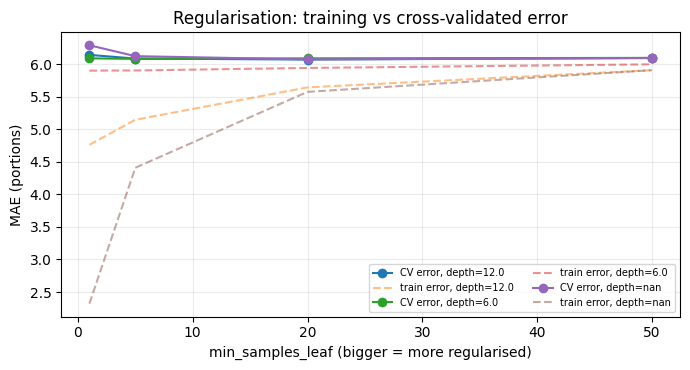

In [14]:
import time; t0 = time.time()
rf_grid = {"max_depth": [6, 12, None], "min_samples_leaf": [1, 5, 20, 50]}
rf_search = tune(lambda **p: RandomForestRegressor(n_estimators=60, random_state=CFG.seed, n_jobs=-1, **p), rf_grid, train)
print(f"Search finished in {time.time()-t0:.0f}s  ({len(rf_search)} settings x 4 date-folds)")
display(rf_search.round(3))
best_rf = {k: (None if pd.isna(v) else int(v)) for k, v in rf_search.loc[0, ["max_depth", "min_samples_leaf"]].items()}
print("Chosen RF settings (lowest CV error):", best_rf)

# the regularisation picture: train error vs CV error as leaves get bigger
fig, ax = plt.subplots(figsize=(7, 3.8))
for depth, part in rf_search.groupby(rf_search["max_depth"].astype(str)):
    part = part.sort_values("min_samples_leaf")
    ax.plot(part.min_samples_leaf, part.cv_MAE, marker="o", label=f"CV error, depth={depth}")
    ax.plot(part.min_samples_leaf, part.train_MAE, ls="--", alpha=.5, label=f"train error, depth={depth}")
ax.set(xlabel="min_samples_leaf (bigger = more regularised)", ylabel="MAE (portions)", title="Regularisation: training vs cross-validated error")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.savefig(FIGS / "03_rf_regularisation.png", dpi=140); plt.show()

**How to read it:** the dashed line (error on data the model has seen) is always lower than the solid line (error on the next block of dates). The **gap** is the overfitting. Stronger regularisation shrinks the gap; we pick the setting where the *solid* line is lowest, not the dashed one.

### 3.5 Validation results and feature importance
The chosen forest is trained on the training dates and scored on the validation dates, which were never used for tuning.

,model,MAE,RMSE,R2,WAPE_%
0,Naive: yesterday (lag_1),8.319,11.053,-0.118,44.743
1,Naive: 7-day average,6.397,8.472,0.343,34.407
2,Random Forest (base),5.887,7.845,0.437,31.666


Overfitting check -> MAE on training data: 5.721 | on unseen validation data: 5.887


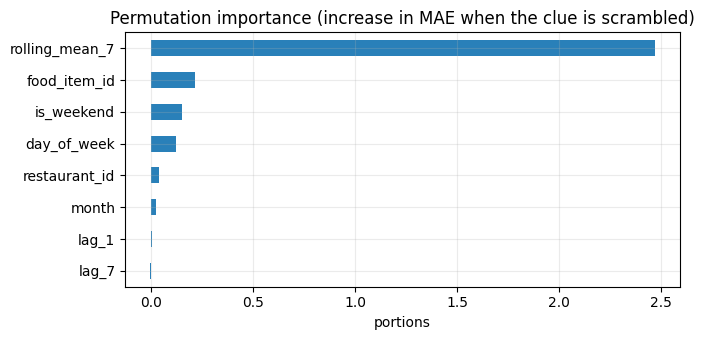

Most useful clues: rolling_mean_7, food_item_id, is_weekend


In [15]:
# ---- (2) fit the chosen forest on TRAIN, score on VALIDATION (dates never used for tuning)
rf_train = make_pipe(RandomForestRegressor(n_estimators=200, random_state=CFG.seed, n_jobs=-1, **best_rf))
rf_train.fit(train[FEATURES], train[TARGET])
val_rf = metrics(valid[TARGET], rf_train.predict(valid[FEATURES]))
tr_rf  = metrics(train[TARGET], rf_train.predict(train[FEATURES]))
val_table = pd.DataFrame(base_rows + [{"model": "Random Forest (base)", **val_rf}]).round(3)
display(val_table)
print(f"Overfitting check -> MAE on training data: {tr_rf['MAE']:.3f} | on unseen validation data: {val_rf['MAE']:.3f}")
val_table.to_csv(REPORTS / "validation_model_comparison.csv", index=False)

# ---- (3) permutation importance: shuffle one clue at a time and see how much the error grows
pi = permutation_importance(rf_train, valid[FEATURES], valid[TARGET], scoring="neg_mean_absolute_error",
                            n_repeats=5, random_state=CFG.seed, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
ax = imp.plot(kind="barh", figsize=(7, 3.5), color="#2980b9"); ax.set(title="Permutation importance (increase in MAE when the clue is scrambled)", xlabel="portions")
plt.tight_layout(); plt.savefig(FIGS / "04_feature_importance.png", dpi=140); plt.show()
print("Most useful clues:", ", ".join(imp.sort_values(ascending=False).index[:3]))

### 3.6 The final test — refit on train + validation, score the **test** dates once
After tuning is finished we give the model all the history we are allowed to use (train + validation) and score the final, untouched test dates. We report the result **whatever it is**, even if a simple baseline wins.

,model,MAE,RMSE,R2,WAPE_%
0,Naive: yesterday (lag_1),8.161,10.865,-0.210,46.478
1,Naive: 7-day average,6.215,8.221,0.307,35.393
2,Random Forest (base),5.739,7.597,0.409,32.683


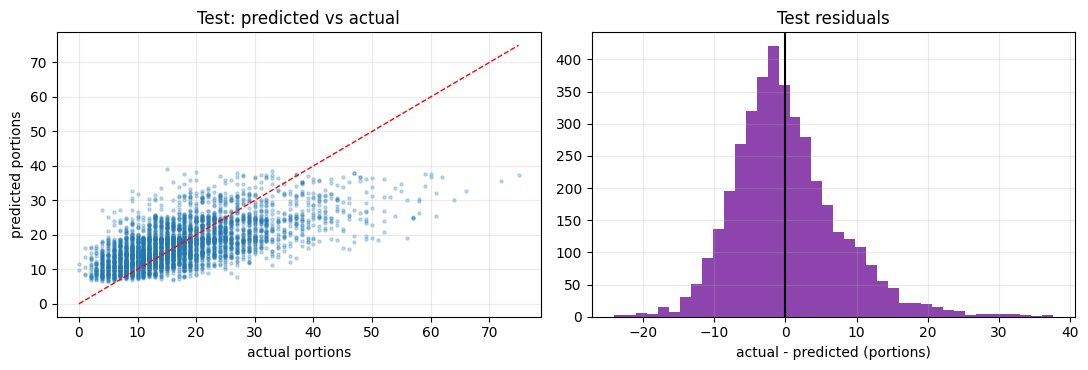

MAE by restaurant:


,MAE
restaurant_id,
1,5.80
2,4.64
3,6.77


Hardest dishes to forecast (highest MAE):


,MAE
name,
Tea,8.26
Chicken Pilau,7.46
Mandazi,7.17
Samosa,6.60


Reminder: all scores come from SYNTHETIC data, not real MloHub demand.


In [16]:
train_valid = pd.concat([train, valid], ignore_index=True)
final_model = make_pipe(RandomForestRegressor(n_estimators=200, random_state=CFG.seed, n_jobs=-1, **best_rf))
final_model.fit(train_valid[FEATURES], train_valid[TARGET])
rf_pred = np.maximum(0, final_model.predict(test[FEATURES]))

test_table = pd.DataFrame([
    {"model": "Naive: yesterday (lag_1)", **metrics(test[TARGET], test["lag_1"])},
    {"model": "Naive: 7-day average",     **metrics(test[TARGET], test["rolling_mean_7"])},
    {"model": "Random Forest (base)",     **metrics(test[TARGET], rf_pred)}]).round(3)
display(test_table)
test_table.to_csv(REPORTS / "test_metrics.csv", index=False)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].scatter(test[TARGET], rf_pred, s=5, alpha=.25); lim = [0, max(test[TARGET].max(), rf_pred.max())]
axs[0].plot(lim, lim, "r--", lw=1); axs[0].set(xlabel="actual portions", ylabel="predicted portions", title="Test: predicted vs actual")
axs[1].hist(test[TARGET].values - rf_pred, bins=40, color="#8e44ad"); axs[1].axvline(0, color="k")
axs[1].set(xlabel="actual - predicted (portions)", title="Test residuals"); plt.tight_layout()
plt.savefig(FIGS / "05_test_evaluation.png", dpi=140); plt.show()

# where is the forest weaker? error per restaurant and per dish
err = test.assign(pred=rf_pred, abs_err=np.abs(test[TARGET] - rf_pred)).merge(
        food[["id", "name"]].assign(id=lambda d: d["id"].astype(str)), left_on="food_item_id", right_on="id", suffixes=("", "_f"))
by_rest = err.groupby("restaurant_id")["abs_err"].mean().round(2).rename("MAE")
by_dish = err.groupby("name")["abs_err"].mean().round(2).sort_values(ascending=False).rename("MAE")
print("MAE by restaurant:"); display(by_rest.to_frame())
print("Hardest dishes to forecast (highest MAE):"); display(by_dish.head(4).to_frame())
print("Reminder: all scores come from SYNTHETIC data, not real MloHub demand.")

## Task 4 · Validating the base model with other methods

### 4.1 The same process, different models

| Model | Why it is a useful check |
|---|---|
| Naïve baselines | The "do nothing clever" yardstick |
| **Ridge Regression** | A *linear* model with built-in regularisation (penalty `alpha`). Tests whether non-linear power is really needed |
| **Decision Tree** | A single tree — shows what the *forest of trees* adds |
| **Gradient Boosting** (HistGradientBoosting) | A different way of combining trees (learns from previous mistakes) — the strongest typical rival on tables |
| **Random Forest** | Our base model |

In [17]:
candidates = {
    "Ridge Regression":  (lambda **p: Ridge(**p),                                         {"alpha": [0.1, 1, 10, 100]}, True),
    "Decision Tree":     (lambda **p: DecisionTreeRegressor(random_state=CFG.seed, **p),  {"max_depth": [4, 8, 12], "min_samples_leaf": [5, 20, 50]}, False),
    "Gradient Boosting": (lambda **p: HistGradientBoostingRegressor(random_state=CFG.seed, **p),
                          {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31], "min_samples_leaf": [20, 50]}, False),
}
compare, tuned = [], {}
for name, (mk, grid, scale) in candidates.items():
    res = tune(mk, grid, train, scale=scale)                       # same date-based CV tuning as the forest
    best = {k: (None if pd.isna(v) else (int(v) if float(v).is_integer() and k not in ("alpha", "learning_rate") else float(v)))
            for k, v in res.iloc[0][list(grid)].items()}      # table stores numbers as floats -> restore ints
    tuned[name] = (mk, best, scale)
    on_train = make_pipe(mk(**best), scale).fit(train[FEATURES], train[TARGET])
    val = metrics(valid[TARGET], on_train.predict(valid[FEATURES]))
    final = make_pipe(mk(**best), scale).fit(train_valid[FEATURES], train_valid[TARGET])
    tst = metrics(test[TARGET], final.predict(test[FEATURES]))
    compare.append({"model": name, "best_settings": str(best), "cv_MAE": res.loc[0, "cv_MAE"],
                    "val_MAE": val["MAE"], "test_MAE": tst["MAE"], "test_RMSE": tst["RMSE"], "test_R2": tst["R2"], "test_WAPE_%": tst["WAPE_%"]})
    print(f"{name:18s} tuned -> {best}")

rf_row = {"model": "Random Forest (base)", "best_settings": str(best_rf), "cv_MAE": rf_search.loc[0, "cv_MAE"],
          "val_MAE": val_rf["MAE"], "test_MAE": metrics(test[TARGET], rf_pred)["MAE"], "test_RMSE": metrics(test[TARGET], rf_pred)["RMSE"],
          "test_R2": metrics(test[TARGET], rf_pred)["R2"], "test_WAPE_%": metrics(test[TARGET], rf_pred)["WAPE_%"]}
nv = {"best_settings": "-", "cv_MAE": np.nan}
for nm, col in [("Naive: yesterday (lag_1)", "lag_1"), ("Naive: 7-day average", "rolling_mean_7")]:
    m_val, m_tst = metrics(valid[TARGET], valid[col]), metrics(test[TARGET], test[col])
    compare.append({"model": nm, **nv, "val_MAE": m_val["MAE"], "test_MAE": m_tst["MAE"], "test_RMSE": m_tst["RMSE"], "test_R2": m_tst["R2"], "test_WAPE_%": m_tst["WAPE_%"]})
compare.append(rf_row)
comparison = pd.DataFrame(compare).sort_values("test_MAE").reset_index(drop=True)
display(comparison.drop(columns="best_settings").round(3))
comparison.to_csv(REPORTS / "model_comparison_all.csv", index=False)

Ridge Regression   tuned -> {'alpha': 100.0}
Decision Tree      tuned -> {'max_depth': 4, 'min_samples_leaf': 50}
Gradient Boosting  tuned -> {'learning_rate': 0.1, 'max_leaf_nodes': 15, 'min_samples_leaf': 50}


,model,cv_MAE,val_MAE,test_MAE,test_RMSE,test_R2,test_WAPE_%
0,Gradient Boosting,5.952,5.783,5.659,7.507,0.423,32.229
1,Ridge Regression,5.962,5.851,5.712,7.574,0.412,32.527
2,Random Forest (base),6.069,5.887,5.739,7.597,0.409,32.683
3,Decision Tree,6.152,6.127,5.949,7.792,0.378,33.882
4,Naive: 7-day average,NaN,6.397,6.215,8.221,0.307,35.393
5,Naive: yesterday (lag_1),NaN,8.319,8.161,10.865,-0.210,46.478


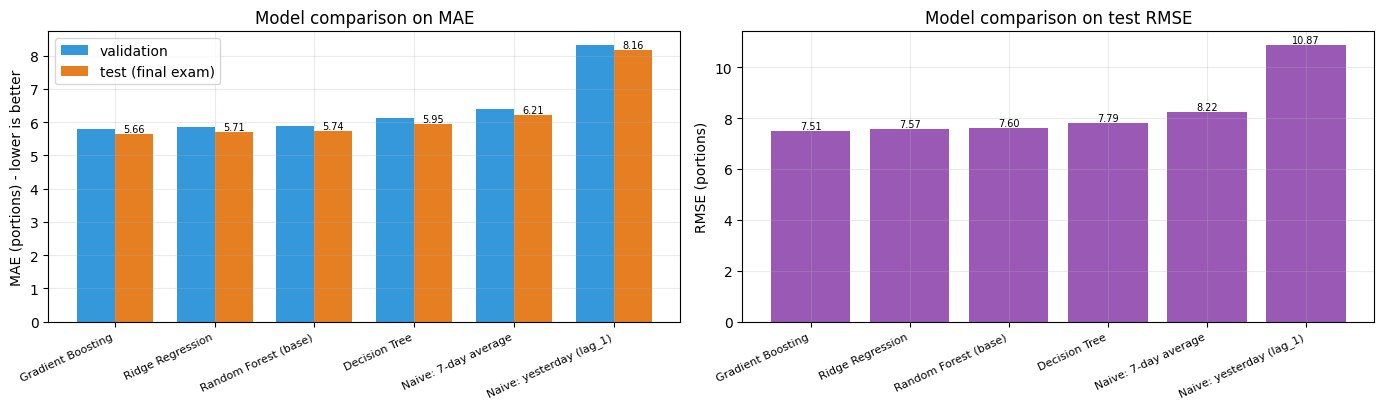

Best on the final test: Gradient Boosting (MAE 5.66).  Random Forest ranks #3 of 6 (MAE 5.74, +1.4% vs the best).
Random Forest improves on the 7-day-average baseline by 7.7%  (MAE 6.21 -> 5.74 portions).
For scale: the fold-to-fold spread of the forest's CV error was about +/-0.46 portions.


In [18]:
# Figure-6 style chart: all models side by side on the same metrics
order = comparison.sort_values("test_MAE")["model"].tolist()
cmp = comparison.set_index("model").loc[order]
x = np.arange(len(cmp)); w = 0.38
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
axs[0].bar(x - w/2, cmp["val_MAE"], w, label="validation", color="#3498db")
axs[0].bar(x + w/2, cmp["test_MAE"], w, label="test (final exam)", color="#e67e22")
axs[0].set_xticks(x); axs[0].set_xticklabels(cmp.index, rotation=25, ha="right", fontsize=8)
axs[0].set(ylabel="MAE (portions) - lower is better", title="Model comparison on MAE"); axs[0].legend()
axs[1].bar(x, cmp["test_RMSE"], color="#9b59b6"); axs[1].set_xticks(x); axs[1].set_xticklabels(cmp.index, rotation=25, ha="right", fontsize=8)
axs[1].set(ylabel="RMSE (portions)", title="Model comparison on test RMSE")
for ax_, col in [(axs[0], "test_MAE"), (axs[1], "test_RMSE")]:
    for i, v in enumerate(cmp[col]): ax_.text(i + (w/2 if ax_ is axs[0] else 0), v, f"{v:.2f}", ha="center", va="bottom", fontsize=7)
plt.tight_layout(); plt.savefig(FIGS / "06_model_comparison.png", dpi=150); plt.show()

winner = comparison.iloc[0]["model"]; rf_rank = int(comparison.index[comparison.model == "Random Forest (base)"][0]) + 1
best_mae = comparison.iloc[0]["test_MAE"]; rf_mae = comparison.loc[comparison.model == "Random Forest (base)", "test_MAE"].iloc[0]
base7 = comparison.loc[comparison.model == "Naive: 7-day average", "test_MAE"].iloc[0]
print(f"Best on the final test: {winner} (MAE {best_mae:.2f}).  Random Forest ranks #{rf_rank} of {len(comparison)} (MAE {rf_mae:.2f}, {100*(rf_mae/best_mae-1):+.1f}% vs the best).")
print(f"Random Forest improves on the 7-day-average baseline by {100*(1-rf_mae/base7):.1f}%  (MAE {base7:.2f} -> {rf_mae:.2f} portions).")
print(f"For scale: the fold-to-fold spread of the forest's CV error was about +/-{rf_search.loc[0, 'cv_MAE_std']:.2f} portions.")

### 4.2 Rolling-origin backtest — is the result stable over time?
A single test period could be lucky. A **backtest** repeats the "train on the past, predict the next block" exam at several points in time using only dates *before* the final test. If the forest beats the baseline in **every** block (and the spread is small), we can trust the result more.

,fold,test_from,test_to,Naive 7-day avg,Ridge,Random Forest
0,1,2024-09-09,2024-11-20,5.646,5.272,5.452
1,2,2024-11-21,2025-02-02,6.471,6.007,6.019
2,3,2025-02-03,2025-04-17,7.106,6.492,6.547
3,4,2025-04-18,2025-06-30,7.078,6.456,6.532
4,5,2025-07-01,2025-09-12,6.184,5.686,5.717


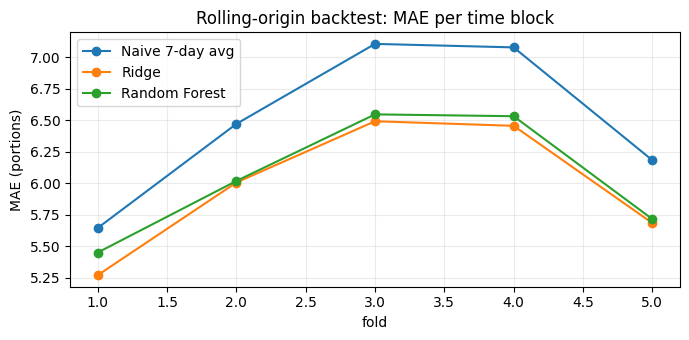

Mean MAE over blocks: {'Naive 7-day avg': 6.497, 'Ridge': 5.983, 'Random Forest': 6.053} | std: {'Naive 7-day avg': 0.618, 'Ridge': 0.519, 'Random Forest': 0.487}
Random Forest beat the 7-day baseline in 5 of 5 blocks.
Ridge beat the forest in 5 of 5 blocks (by an average of 0.071 portions).


In [19]:
bt_rows = []
tv = train_valid.reset_index(drop=True)
for k, (tri, vai) in enumerate(date_folds(tv, n_splits=5, first_train_frac=0.40), start=1):
    ytrue = tv.loc[vai, TARGET]
    rf_k = make_pipe(RandomForestRegressor(n_estimators=100, random_state=CFG.seed, n_jobs=-1, **best_rf)).fit(tv.loc[tri, FEATURES], tv.loc[tri, TARGET])
    rd_mk, rd_best, rd_sc = tuned["Ridge Regression"]
    rd_k = make_pipe(rd_mk(**rd_best), rd_sc).fit(tv.loc[tri, FEATURES], tv.loc[tri, TARGET])
    bt_rows.append({"fold": k, "test_from": tv.loc[vai, "date"].min().date(), "test_to": tv.loc[vai, "date"].max().date(),
                    "Naive 7-day avg": mean_absolute_error(ytrue, tv.loc[vai, "rolling_mean_7"]),
                    "Ridge": mean_absolute_error(ytrue, np.maximum(0, rd_k.predict(tv.loc[vai, FEATURES]))),
                    "Random Forest": mean_absolute_error(ytrue, np.maximum(0, rf_k.predict(tv.loc[vai, FEATURES])))})
bt = pd.DataFrame(bt_rows); display(bt.round(3))
ax = bt.set_index("fold")[["Naive 7-day avg", "Ridge", "Random Forest"]].plot(marker="o", figsize=(7, 3.5))
ax.set(ylabel="MAE (portions)", title="Rolling-origin backtest: MAE per time block"); plt.tight_layout()
plt.savefig(FIGS / "07_backtest.png", dpi=140); plt.show()
m = bt[["Naive 7-day avg", "Ridge", "Random Forest"]]
print("Mean MAE over blocks:", m.mean().round(3).to_dict(), "| std:", m.std().round(3).to_dict())
print("Random Forest beat the 7-day baseline in", int((bt["Random Forest"] < bt["Naive 7-day avg"]).sum()), "of", len(bt), "blocks.")
print("Ridge beat the forest in", int((bt["Ridge"] < bt["Random Forest"]).sum()), "of", len(bt), "blocks (by an average of", f"{(bt['Random Forest']-bt['Ridge']).mean():.3f}", "portions).")
bt.to_csv(REPORTS / "rolling_backtest.csv", index=False)

## Saving the engine for the MloHub app
The whole pipeline (encoding + forest) is saved as one `.joblib` file plus a `model_manifest.json` ("passport": features, dates, versions, scores, checksum). Django will later load it; Kotlin only talks to Django and never touches the file.
*Security rule:* only load `.joblib` files you created yourself — they can run code when opened.

In [20]:
MODEL_PATH = MODELS / "mlohub_demand_forecast_rf_v1.joblib"
joblib.dump(final_model, MODEL_PATH, compress=3)
reloaded = joblib.load(MODEL_PATH)                                    # our own, trusted file
assert np.allclose(reloaded.predict(test[FEATURES].head(20)), final_model.predict(test[FEATURES].head(20)))
manifest = {"project": "MLOHub", "artifact_version": "1.0", "task": "one_day_ahead_quantity_sold", "synthetic": True,
            "features": FEATURES, "target": TARGET, "timezone": CFG.timezone, "random_seed": CFG.seed,
            "training_dates": {"from": str(train_valid.date.min().date()), "to": str(train_valid.date.max().date())},
            "test_dates": {"from": str(test.date.min().date()), "to": str(test.date.max().date())},
            "forest_hyperparameters": best_rf, "test_metrics": test_table.to_dict(orient="records"),
            "scikit_learn_version": sklearn.__version__, "pandas_version": pd.__version__, "python_version": platform.python_version(),
            "artifact_sha256": hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest(),
            "warning": "Synthetic proof of concept only; not approved for real stock decisions."}
(MODELS / "model_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Saved:", MODEL_PATH.name, f"({MODEL_PATH.stat().st_size/1e6:.2f} MB) | reload test PASSED")

# one example prediction exactly as the app will request it: 5 dishes of Campus Bites for the day after the data ends
tomorrow = daily["date"].max() + pd.Timedelta(days=1)
rows = []
for (rid, fid), part in daily[daily.restaurant_id == 1].groupby(["restaurant_id", "food_item_id"]):
    qv = part.sort_values("date")["quantity_sold"].to_numpy()
    rows.append({"restaurant_id": str(rid), "food_item_id": str(fid), "day_of_week": tomorrow.dayofweek, "month": tomorrow.month,
                 "is_weekend": int(tomorrow.dayofweek >= 5), "lag_1": float(qv[-1]), "lag_7": float(qv[-7]), "rolling_mean_7": float(qv[-7:].mean())})
nxt = pd.DataFrame(rows)[FEATURES]
fc = nxt[["restaurant_id", "food_item_id"]].assign(forecast_date=str(tomorrow.date()),
        predicted_portions=np.maximum(0, reloaded.predict(nxt)).round(1))
fc = fc.merge(food[["id", "name"]].assign(id=lambda d: d["id"].astype(str)), left_on="food_item_id", right_on="id").drop(columns="id")
fc.to_csv(PREDS / "next_day_forecast_synthetic.csv", index=False)
display(fc.sort_values("predicted_portions", ascending=False).head(6))

Saved: mlohub_demand_forecast_rf_v1.joblib (3.19 MB) | reload test PASSED


,restaurant_id,food_item_id,forecast_date,predicted_portions,name
9,1,110,2025-12-31,29.7,Tea
0,1,101,2025-12-31,24.5,Chicken Pilau
3,1,104,2025-12-31,24.0,Samosa
2,1,103,2025-12-31,23.8,Vegetable Rice
1,1,102,2025-12-31,22.1,Beef Stew
10,1,111,2025-12-31,20.9,Mandazi
